# Checking visibility, system survival, and memory parity

We build the circuit gate by gate, read its probabilities, and compare them with the formulas in the manuscript. The circuit calculation does not use those formulas to generate its answers.

We test both schedule outcomes, equal and unequal gaps between records, and a dephased schedule. A separate matrix calculation checks the simulator itself.

Everything here is ideal and noiseless. See [Memory parity with noise](memory_parity_robustness.ipynb) for relaxation, dephasing, and readout errors. Run from top to bottom; results go in `outputs/ideal_verification/`. No quantum hardware or account is needed.

## 1. What we are checking

For example, take three recording interactions. The system rotates, records into the first memory, rotates again, records into the second, and so on. The gaps between records do not have to be equal.

We call the schedule qubit $Q$, the system $S$, and the memories $M_1,\ldots,M_N$. Every memory starts in zero. The system also starts in zero. The drive strength is $\Omega$, and the time before recording $k$ is $\Delta t_k$. The corresponding rotation angle is $\theta_k=\Omega\Delta t_k$. The extra schedule delay is $\delta$, with angle $\alpha=\Omega\delta$.

Schedule A puts that extra rotation **after** the recording sequence. Schedule B puts it **before**. Everything inside the recording sequence is identical in the two branches.

| Quantity | Prediction to check |
|---|---|
| Schedule visibility | $\mathcal V=\cos^2(\alpha/2)$ |
| Zero-offset reference | $P_{0,\mathrm{ref}}=\tfrac12[1+\prod_k\cos\theta_k]$ |
| Minus-selected system | $P(S=0\mid Q=-)=1-P_{0,\mathrm{ref}}$ |
| Minus-selected memory parity | $\langle X_{M_1}\cdots X_{M_N}\rangle_-=-1$ |
| Plus-selected memory parity | $\langle X_{M_1}\cdots X_{M_N}\rangle_+=p_-/p_+$ |
| Schedule outcome probabilities | $p_-=\tfrac12\sin^2(\alpha/2)$ and $p_+=1-p_-$ |

The product of cosines is the uneven-spacing version of $\cos^N(\Omega\Delta t)$. In the reference calculation we use exactly the same intervals, but set the extra delay to zero. Ignoring $Q$ in the delayed run is a different experiment and is not the reference.

The minus predictions need $p_->0$. At $\alpha=2\pi k$, the minus outcome never happens, so a conditional probability for it is undefined.

In [1]:
from pathlib import Path
import csv
import hashlib
import json
import platform
import sys
import numpy as np
import scipy
from scipy.linalg import expm
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

SEED = 20261105
ATOL = 2e-10
MIN_SELECTED_PROB = 1e-12
OUT = Path("outputs") / "ideal_verification"
OUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"font.size": 11, "figure.dpi": 120})

def show_table(headers, rows):
    lines = ["| " + " | ".join(headers) + " |",
             "| " + " | ".join(["---"] * len(headers)) + " |"]
    lines += ["| " + " | ".join(map(str, row)) + " |" for row in rows]
    display(Markdown("\n".join(lines)))

print("Python", platform.python_version())
print("NumPy", np.__version__, "SciPy", scipy.__version__,
      "Matplotlib", matplotlib.__version__)
print("Random seed:", SEED)
print("Absolute tolerance:", ATOL)

Python 3.9.6
NumPy 2.0.2 SciPy 1.13.1 Matplotlib 3.9.4
Random seed: 20261105
Absolute tolerance: 2e-10


## 2. Build the gates

A state vector stores one complex amplitude for each bit string. We use the order $Q,S,M_1,\ldots,M_N$, with $Q$ on the left. Qubit numbers in the code start at zero.

A rotation mixes the amplitudes for system zero and system one. A CNOT swaps a memory’s zero and one amplitudes only when the system is one. These functions act on amplitudes; they do not contain the visibility, complement, or parity formulas.

In [2]:
I2 = np.eye(2, dtype=complex)
X = np.array([[0, 1], [1, 0]], dtype=complex)
H = np.array([[1, 1], [1, -1]], dtype=complex) / np.sqrt(2)

def rx(angle):
    return np.cos(angle / 2) * I2 - 1j * np.sin(angle / 2) * X

def gate(state, matrix, target, nqubits, control=None, control_value=1):
    """Apply a gate to one qubit, optionally controlled by another qubit."""
    labels = np.arange(state.size)
    target_bit = 1 << (nqubits - 1 - target)
    use = (labels & target_bit) == 0
    if control is not None:
        control_bit = 1 << (nqubits - 1 - control)
        use &= ((labels & control_bit) != 0) == bool(control_value)
    zero = labels[use]
    one = zero | target_bit
    out = state.copy()
    out[zero] = matrix[0, 0] * state[zero] + matrix[0, 1] * state[one]
    out[one] = matrix[1, 0] * state[zero] + matrix[1, 1] * state[one]
    return out

def simulate(intervals, omega, delta, preparation="coherent", record=True):
    """Return the circuit state just before the final Hadamard on Q."""
    intervals = np.asarray(intervals, dtype=float)
    if intervals.ndim != 1 or not np.all(np.isfinite(intervals)):
        raise ValueError("Give the intervals as a finite, one-dimensional list.")
    if np.any(intervals < 0) or not np.isfinite(omega + delta) or delta < 0:
        raise ValueError("Intervals and the schedule delay must be nonnegative.")
    nqubits = len(intervals) + 2
    state = np.zeros(2 ** nqubits, dtype=complex)
    state[0] = 1
    if preparation == "coherent":
        state = gate(state, H, 0, nqubits)
    elif preparation == "B":
        state = gate(state, X, 0, nqubits)
    elif preparation != "A":
        raise ValueError("Choose coherent, A, or B preparation.")
    # B gets the extra rotation first.
    state = gate(state, rx(omega * delta), 1, nqubits, control=0)
    for k, interval in enumerate(intervals):
        state = gate(state, rx(omega * interval), 1, nqubits)
        if record:
            state = gate(state, X, k + 2, nqubits, control=1)
    # A gets the same extra rotation last.
    state = gate(state, rx(omega * delta), 1, nqubits,
                 control=0, control_value=0)
    return state

## 3. Read out the circuit

A Hadamard on $Q$ turns its plus/minus measurement into an ordinary zero/one readout: zero means plus, and one means minus.

To measure memory **X parity**, we also apply a Hadamard to each memory. Each measured zero contributes $+1$ and each measured one contributes $-1$. Multiplying those signs gives $-1$ when an odd number of memories read one. Thus, parity $-1$ means every selected shot has odd parity; it does not mean that every memory reads one.

We calculate the probabilities of all bit strings after those gates. We also calculate parity directly from the X operator as a second check. A group with probability below the stated cutoff is reported as undefined, rather than divided by a nearly zero number.

In [3]:
def readout(ensemble, N):
    """Read one pure state or a weighted mixture of circuit states."""
    nqubits = N + 2
    size_m = 2 ** N
    rho_q = np.zeros((2, 2), dtype=complex)
    z_prob = np.zeros((2, 2, size_m))
    x_prob = np.zeros_like(z_prob)
    parity_joint_direct = np.zeros(2)
    flip_all_memories = np.arange(size_m) ^ (size_m - 1)
    for weight, state in ensemble:
        q_rest = state.reshape(2, -1)
        rho_q += weight * (q_rest @ q_rest.conj().T)
        after_q = gate(state, H, 0, nqubits)
        grouped = after_q.reshape(2, 2, size_m)
        z_prob += weight * np.abs(grouped) ** 2
        for q in (0, 1):
            parity_joint_direct[q] += weight * np.vdot(
                grouped[q], grouped[q][:, flip_all_memories]).real
        after_m = after_q
        for memory in range(2, nqubits):
            after_m = gate(after_m, H, memory, nqubits)
        x_prob += weight * np.abs(after_m.reshape(2, 2, size_m)) ** 2
    odd = np.array([bin(m).count("1") % 2 == 1 for m in range(size_m)])
    p = z_prob.sum(axis=(1, 2))
    system_zero_joint = z_prob[:, 0, :].sum(axis=1)
    odd_joint = x_prob[:, :, odd].sum(axis=(1, 2))
    even_joint = x_prob[:, :, ~odd].sum(axis=(1, 2))
    parity_joint = even_joint - odd_joint
    safe = p > MIN_SELECTED_PROB
    def conditional(joint):
        return np.divide(joint, p, out=np.full(2, np.nan), where=safe)
    return dict(visibility=2 * abs(rho_q[0, 1]),
                overlap=2 * rho_q[0, 1], p=p,
                system_zero_joint=system_zero_joint,
                system_zero=conditional(system_zero_joint),
                parity_joint=parity_joint, parity=conditional(parity_joint),
                parity_joint_direct=parity_joint_direct,
                odd_joint=odd_joint, even_joint=even_joint,
                odd=conditional(odd_joint), even=conditional(even_joint),
                z_prob=z_prob, x_prob=x_prob,
                norm=float(np.trace(rho_q).real))

def run_case(intervals, omega, delta):
    state = simulate(intervals, omega, delta)
    return readout([(1.0, state)], len(intervals))

## 4. Try one uneven recording sequence

Here the intervals are 0.12, 0.55, and 1.03 in arbitrary time units. We choose the drive strength in the matching inverse-time units. Only the products $\Omega\Delta t_k$ and $\Omega\delta$ affect this ideal circuit.

We use $\Omega\delta=\pi/2$. The predicted minus fraction is one quarter, and the plus parity should be $1/3$. The minus parity should be exactly $-1$. The table below comes from the simulated amplitudes.

In [4]:
example_intervals = np.array([0.12, 0.55, 1.03])
example_omega = 1.4
example_delta = np.pi / (2 * example_omega)
example = run_case(example_intervals, example_omega, example_delta)
reference = run_case(example_intervals, example_omega, 0.0)
reference_zero = reference["system_zero_joint"].sum()
show_table(["Q outcome", "Fraction of runs", "P(S = 0)",
            "Mean X parity", "Odd parity", "Even parity"],
           [[name] + [f"{example[key][q]:.9f}" for key in
            ["p", "system_zero", "parity", "odd", "even"]]
            for q, name in enumerate(["plus", "minus"])])
print(f"Reference P(S = 0): {reference_zero:.12f}")
print(f"Reference + minus-selected P(S = 0): "
      f"{reference_zero + example['system_zero'][1]:.12f}")
assert abs(example["parity"][1] + 1) < ATOL
assert abs(example["parity"][0] - 1/3) < ATOL
assert abs(reference_zero + example["system_zero"][1] - 1) < ATOL

| Q outcome | Fraction of runs | P(S = 0) | Mean X parity | Odd parity | Even parity |
| --- | --- | --- | --- | --- | --- |
| plus | 0.750000000 | 0.510012334 | 0.333333333 | 0.333333333 | 0.666666667 |
| minus | 0.250000000 | 0.454544682 | -1.000000000 | 1.000000000 | 0.000000000 |

Reference P(S = 0): 0.545455317689
Reference + minus-selected P(S = 0): 1.000000000000


## 5. Check the simulator with full matrices

For a few small circuits, we build the whole gate matrix using tensor products. Rotations come from a matrix exponential, rather than the sine-and-cosine function above. Controlled gates are built from projectors, rather than swapping entries by their bit labels.

This is slower, but it is a useful independent check of qubit order, controls, and gate order. We compare the complete complex state, not just one observable. Neither method uses the paper’s final formulas.

In [5]:
def kron_all(factors):
    result = np.array([[1.0 + 0j]])
    for factor in factors:
        result = np.kron(result, factor)
    return result

def dense_circuit(intervals, omega, delta):
    n = len(intervals) + 2
    p0 = np.diag([1.0, 0.0])
    p1 = np.diag([0.0, 1.0])
    def single(matrix, target):
        factors = [I2] * n
        factors[target] = matrix
        return kron_all(factors)
    def controlled(matrix, target, control, value):
        off, on = [I2] * n, [I2] * n
        off[control] = p1 if value == 0 else p0
        on[control] = p0 if value == 0 else p1
        on[target] = matrix
        return kron_all(off) + kron_all(on)
    def rotation(time):
        return expm(-0.5j * omega * time * X)
    state = np.zeros(2 ** n, dtype=complex)
    state[0] = 1
    state = single(H, 0) @ state
    state = controlled(rotation(delta), 1, 0, 1) @ state
    for k, interval in enumerate(intervals):
        state = single(rotation(interval), 1) @ state
        state = controlled(X, k + 2, 1, 1) @ state
    return controlled(rotation(delta), 1, 0, 0) @ state

check_rng = np.random.default_rng(SEED + 1)
dense_errors = []
for N in range(1, 5):
    for _ in range(8):
        intervals = check_rng.uniform(0.01, 2.0, N)
        omega = check_rng.uniform(0.2, 4.0)
        delta = check_rng.uniform(0.0, 3.0)
        fast = simulate(intervals, omega, delta)
        dense = dense_circuit(intervals, omega, delta)
        dense_errors.append(float(np.max(np.abs(fast - dense))))
print("Small circuits checked:", len(dense_errors))
print(f"Largest amplitude difference: {max(dense_errors):.3e}")
assert max(dense_errors) < ATOL

Small circuits checked: 32
Largest amplitude difference: 4.441e-16


## 6. Put the paper’s formulas in a separate function

Now that the numerical calculation is in place, we write down the predictions. This function is only used for comparison. The gate simulator never calls it.

For uneven intervals, let $c=\prod_k\cos(\Omega\Delta t_k)$. Then the reference is $(1+c)/2$, and the minus-selected system probability is $(1-c)/2$. We also check the joint probabilities before dividing by $p_-$. That matters when the minus outcome is very rare.

In [6]:
def predictions(intervals, omega, delta):
    alpha = omega * delta
    visibility = np.cos(alpha / 2) ** 2
    p_minus = 0.5 * np.sin(alpha / 2) ** 2
    p_plus = 1 - p_minus
    product = np.prod(np.cos(omega * np.asarray(intervals)))
    return dict(visibility=visibility, p_plus=p_plus, p_minus=p_minus,
                reference=0.5 * (1 + product),
                system_minus=0.5 * (1 - product),
                parity_minus=-1.0, parity_plus=p_minus / p_plus)

def compare(intervals, omega, delta):
    N = len(intervals)
    measured = run_case(intervals, omega, delta)
    ref = run_case(intervals, omega, 0.0)
    expected = predictions(intervals, omega, delta)
    reference_zero = ref["system_zero_joint"].sum()
    errors = {
        "visibility": abs(measured["overlap"] - expected["visibility"]),
        "reference": abs(reference_zero - expected["reference"]),
        "schedule_probability": abs(measured["p"][1] - expected["p_minus"]),
        "complement": abs(measured["system_zero"][1] + reference_zero - 1),
        "minus_formula": abs(measured["system_zero"][1] - expected["system_minus"]),
        "minus_parity": abs(measured["parity"][1] + 1),
        "plus_parity": abs(measured["parity"][0] - expected["parity_plus"]),
        "wrong_parity_probability": abs(measured["even"][1]),
        "unread_parity": abs(measured["parity_joint"].sum()),
        "two_parity_methods": np.max(np.abs(measured["parity_joint"] -
                                           measured["parity_joint_direct"])),
        "joint_complement": abs(measured["system_zero_joint"][1] -
                                expected["p_minus"] * (1 - reference_zero)),
        "normalization": max(abs(measured["norm"] - 1),
                             abs(measured["p"].sum() - 1),
                             abs(measured["x_prob"].sum() - 1)),
    }
    return measured, expected, {key: float(value) for key, value in errors.items()}

## 7. Try many randomly chosen parameters

We test 600 circuits: 30 equally spaced and 30 unevenly spaced sequences for each $N=1,\ldots,10$. Within a run, $\Omega$ stays constant and both schedules use the same interval list. We vary the total drive angle from 0.02 to 20 radians, so the sample includes both small rotations and substantial evolution.

For the uneven cases, random positive fractions split the total time. Some sequences are nearly balanced; others put most of the time into one or two gaps. With one recording there is only one interval, so “uneven” makes no distinction at $N=1$.

The offset angle ranges from 0.05 to $2\pi-0.05$. We deliberately check zero and very small offsets separately below. The random seed is fixed, and the saved table contains every interval, so the test can be repeated exactly. Numerical agreement is a check of the algebra, not a replacement for its proof.

In [7]:
rng = np.random.default_rng(SEED)
rows = []
for N in range(1, 11):
    for spacing in ("uniform", "nonuniform"):
        for trial in range(30):
            omega = float(rng.uniform(0.15, 5.0))
            total_angle = float(np.exp(rng.uniform(np.log(0.02), np.log(20.0))))
            T = total_angle / omega
            if spacing == "uniform":
                intervals = np.full(N, T / N)
            else:
                concentration = float(rng.choice([0.25, 1.0, 4.0]))
                intervals = T * rng.dirichlet(np.full(N, concentration))
            alpha = float(rng.uniform(0.05, 2 * np.pi - 0.05))
            delta = alpha / omega
            measured, expected, errors = compare(intervals, omega, delta)
            assert all(np.isfinite(v) and v < ATOL for v in errors.values()), (
                N, spacing, trial, intervals, omega, delta, errors)
            rows.append(dict(N=N, spacing=spacing, trial=trial, omega=omega,
                             T=T, delta=delta, alpha=alpha,
                             intervals=json.dumps(intervals.tolist()),
                             visibility=measured["visibility"],
                             expected_visibility=expected["visibility"],
                             system_minus=measured["system_zero"][1],
                             expected_system_minus=expected["system_minus"],
                             p_minus=measured["p"][1],
                             parity_minus=measured["parity"][1],
                             parity_plus=measured["parity"][0],
                             **{"error_" + k: v for k, v in errors.items()}))
error_names = list(errors)
max_errors = {key: max(row["error_" + key] for row in rows) for key in error_names}
show_table(["Check", "Largest absolute difference", "Result"],
           [[key.replace("_", " "), f"{value:.3e}", "pass"]
            for key, value in max_errors.items()])
print(f"All {len(rows)} random circuits passed at tolerance {ATOL:g}.")
with (OUT / "random_cases.csv").open("w", newline="") as f:
    writer = csv.DictWriter(f, fieldnames=list(rows[0]))
    writer.writeheader()
    writer.writerows(rows)

| Check | Largest absolute difference | Result |
| --- | --- | --- |
| visibility | 1.443e-15 | pass |
| reference | 1.665e-15 | pass |
| schedule probability | 6.661e-16 | pass |
| complement | 1.887e-15 | pass |
| minus formula | 8.327e-16 | pass |
| minus parity | 1.521e-14 | pass |
| plus parity | 5.614e-15 | pass |
| wrong parity probability | 1.958e-29 | pass |
| unread parity | 6.828e-15 | pass |
| two parity methods | 5.551e-15 | pass |
| joint complement | 8.327e-16 | pass |
| normalization | 3.553e-15 | pass |

All 600 random circuits passed at tolerance 2e-10.


## 8. Look at the agreement

The first two panels compare circuit results with the formulas. Points on the diagonal mean agreement. The last panel shows the largest error at each memory count, including the parity checks. Tiny differences at this scale come from floating-point arithmetic.

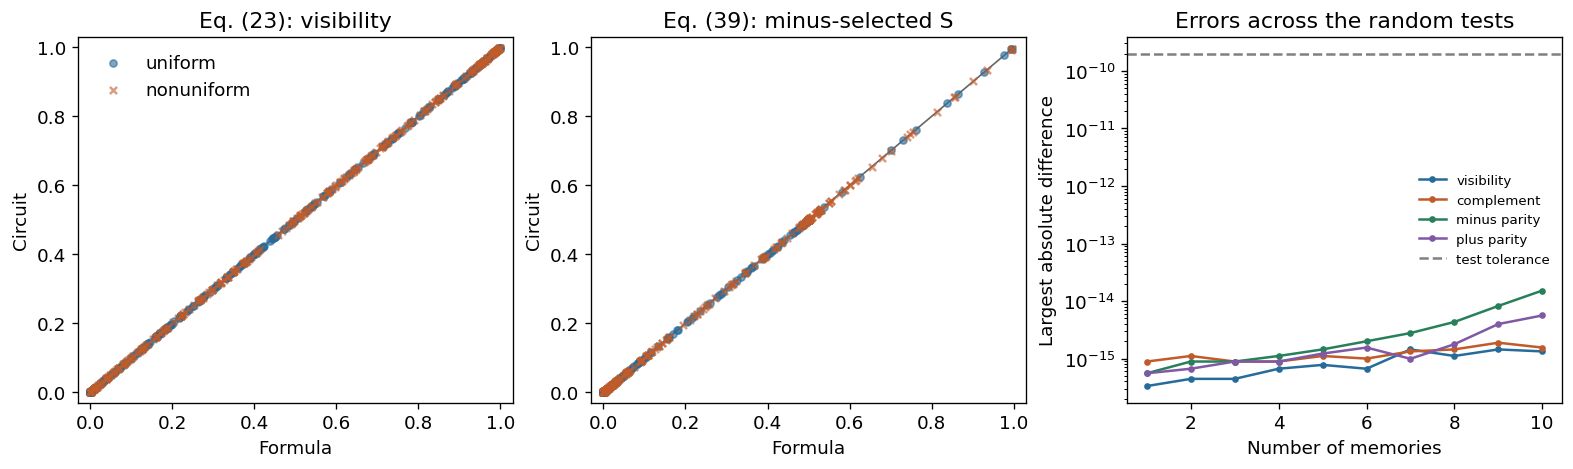

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), constrained_layout=True)
for spacing, marker, color in [("uniform", "o", "#276b9a"),
                                ("nonuniform", "x", "#c15b2a")]:
    subset = [r for r in rows if r["spacing"] == spacing]
    axes[0].scatter([r["expected_visibility"] for r in subset],
                    [r["visibility"] for r in subset], s=18, marker=marker,
                    alpha=0.6, color=color, label=spacing)
    axes[1].scatter([r["expected_system_minus"] for r in subset],
                    [r["system_minus"] for r in subset], s=18, marker=marker,
                    alpha=0.6, color=color)
for ax, title in zip(axes[:2], ["Eq. (23): visibility", "Eq. (39): minus-selected S"]):
    ax.plot([0, 1], [0, 1], color="0.4", lw=1, zorder=0)
    ax.set(xlabel="Formula", ylabel="Circuit", title=title,
           xlim=(-0.03, 1.03), ylim=(-0.03, 1.03))
axes[0].legend(frameon=False)
for key, color in [("visibility", "#276b9a"), ("complement", "#c15b2a"),
                    ("minus_parity", "#27805b"), ("plus_parity", "#8059a4")]:
    values = [max(r["error_" + key] for r in rows if r["N"] == n)
              for n in range(1, 11)]
    axes[2].semilogy(range(1, 11), np.maximum(values, 1e-18), "o-",
                     ms=3, color=color, label=key.replace("_", " "))
axes[2].axhline(ATOL, color="0.5", ls="--", label="test tolerance")
axes[2].set(xlabel="Number of memories", ylabel="Largest absolute difference",
            title="Errors across the random tests")
axes[2].legend(frameon=False, fontsize=8)
fig.savefig(OUT / "random_verification.png", dpi=180)
plt.show()

## 9. Compare coherent and dephased schedules

A dephased schedule has no interference between A and B. We represent it as a 50/50 mixture of two actual circuit runs, one prepared in A and one in B. We add their probabilities, not their amplitudes. This is exactly the result of completely dephasing $Q$ in the schedule basis before the final Hadamard.

For this control, both plus and minus groups should have zero mean X parity. Zero mean means equal probabilities of even and odd parity. A classical random choice of schedule gives the same memory mixture; without a physical schedule qubit there is no plus/minus label to condition on.

In the coherent case, the minus group should stay at $-1$. The plus group varies with the offset and equals $p_-/p_+$. This is why checking both groups matters.

All 600 dephased controls passed; largest difference from zero parity or half-probability: 8.882e-16


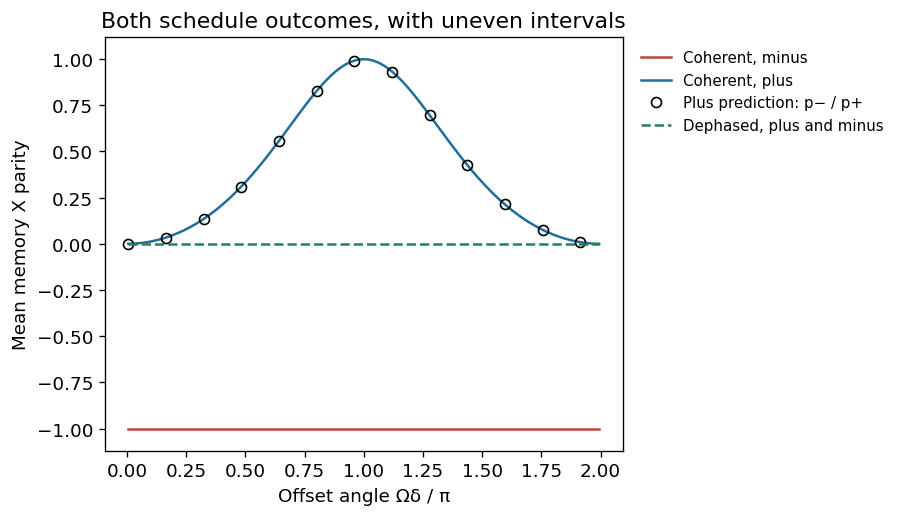

In [9]:
def dephased_case(intervals, omega, delta):
    ensemble = [(0.5, simulate(intervals, omega, delta, preparation=label))
                for label in ("A", "B")]
    return readout(ensemble, len(intervals))

control_errors = []
for row in rows:
    intervals = np.array(json.loads(row["intervals"]))
    control = dephased_case(intervals, row["omega"], row["delta"])
    control_errors.append(max(abs(control["visibility"]),
                              np.max(np.abs(control["parity"])),
                              np.max(np.abs(control["p"] - 0.5))))
assert max(control_errors) < ATOL
print(f"All {len(rows)} dephased controls passed; largest difference "
      f"from zero parity or half-probability: {max(control_errors):.3e}")

alphas = np.linspace(0.02, 2 * np.pi - 0.02, 101)
coherent_parities, dephased_parities = [], []
for alpha in alphas:
    coherent_parities.append(run_case(example_intervals, example_omega,
                                     alpha / example_omega)["parity"])
    dephased_parities.append(dephased_case(example_intervals, example_omega,
                                          alpha / example_omega)["parity"])
coherent_parities = np.array(coherent_parities)
dephased_parities = np.array(dephased_parities)
fig, ax = plt.subplots(figsize=(7.4, 4.2), constrained_layout=True)
ax.plot(alphas / np.pi, coherent_parities[:, 1], color="#b44a39", label="Coherent, minus")
ax.plot(alphas / np.pi, coherent_parities[:, 0], color="#226e99", label="Coherent, plus")
pminus_line = 0.5 * np.sin(alphas / 2) ** 2
ax.plot(alphas[::8] / np.pi, (pminus_line / (1 - pminus_line))[::8],
        "o", mfc="none", color="black", label="Plus prediction: p− / p+")
ax.plot(alphas / np.pi, dephased_parities[:, 0], "--", color="#27805b",
        label="Dephased, plus and minus")
ax.set(xlabel="Offset angle Ωδ / π", ylabel="Mean memory X parity",
       title="Both schedule outcomes, with uneven intervals", ylim=(-1.12, 1.12))
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False, fontsize=9)
fig.savefig(OUT / "memory_parity.png", dpi=180)
plt.show()

## 10. Check boundaries and very rare minus outcomes

We now test cases the random sample does not hit exactly: zero delay, a full-turn delay, a half-turn delay, no drive, and intervals of zero length. Zero-length intervals are mathematical boundary checks, not a proposed hardware schedule.

We also disable all recording CNOTs. Then the two branches are the same rotations in a different order, so visibility must return to one. The visibility formula is not the prediction for this no-recording control. With no memories at all, memory parity is not a witness, so we do not apply the parity claim to that case.

Finally, we make the delay very small. Below our probability cutoff, we still test joint probabilities but leave conditional quantities undefined. This avoids claiming a measured minus-state property when there are effectively no minus events to normalize.

In [10]:
boundary_cases = [
    ("zero delay", [0.2, 0.7, 0.4], 1.0, 0.0),
    ("full-turn delay", [0.2, 0.7, 0.4], 1.0, 2 * np.pi),
    ("half-turn delay", [0.2, 0.7, 0.4], 1.0, np.pi),
    ("no drive", [0.2, 0.7, 0.4], 0.0, 0.9),
    ("zero-length gaps", [0.0, 0.0, 0.8], 1.0, 0.7),
    ("all gaps zero", [0.0, 0.0, 0.0], 1.0, 0.7),
    ("one memory", [0.8], 1.0, 0.7),
]
boundary_rows = []
for label, intervals, omega, delta in boundary_cases:
    got, expected, errors = compare(intervals, omega, delta)
    valid_errors = {k: v for k, v in errors.items() if np.isfinite(v)}
    assert max(valid_errors.values()) < ATOL
    if expected["p_minus"] <= MIN_SELECTED_PROB:
        assert np.isnan(got["parity"][1]) and np.isnan(got["system_zero"][1])
    boundary_rows.append([label, f"{got['p'][1]:.3e}",
                          "undefined" if np.isnan(got["parity"][1])
                          else f"{got['parity'][1]:.9f}"])
for intervals in ([0.2, 0.7, 0.4], []):
    state = simulate(intervals, 1.0, 1.7, record=False)
    got = readout([(1.0, state)], len(intervals))
    assert abs(got["visibility"] - 1) < ATOL
    assert got["p"][1] < MIN_SELECTED_PROB
show_table(["Case", "Minus probability", "Minus X parity"], boundary_rows)
print("Both no-recording controls have unit visibility and no minus outcome.")

rare_rows = []
for alpha in [1e-1, 1e-3, 1e-5, 1e-7, 1e-9, 1e-12, 0.0]:
    got, expected, errors = compare(example_intervals, example_omega,
                                    alpha / example_omega)
    assert errors["joint_complement"] < ATOL
    assert errors["schedule_probability"] < ATOL
    if got["p"][1] > MIN_SELECTED_PROB:
        assert errors["minus_parity"] < ATOL
        assert errors["complement"] < ATOL
    rare_rows.append([f"{alpha:.0e}", f"{got['p'][1]:.3e}",
                      f"{errors['joint_complement']:.3e}",
                      "undefined" if np.isnan(got["parity"][1])
                      else f"{got['parity'][1]:.9f}"])
show_table(["Offset angle", "Minus probability", "Joint-probability error",
            "Minus X parity"], rare_rows)

| Case | Minus probability | Minus X parity |
| --- | --- | --- |
| zero delay | 0.000e+00 | undefined |
| full-turn delay | 7.355e-33 | undefined |
| half-turn delay | 5.000e-01 | -1.000000000 |
| no drive | 0.000e+00 | undefined |
| zero-length gaps | 5.879e-02 | -1.000000000 |
| all gaps zero | 5.879e-02 | -1.000000000 |
| one memory | 5.879e-02 | -1.000000000 |

Both no-recording controls have unit visibility and no minus outcome.


| Offset angle | Minus probability | Joint-probability error | Minus X parity |
| --- | --- | --- | --- |
| 1e-01 | 1.249e-03 | 0.000e+00 | -1.000000000 |
| 1e-03 | 1.250e-07 | 1.800e-21 | -1.000000000 |
| 1e-05 | 1.250e-11 | 7.786e-24 | -1.000000000 |
| 1e-07 | 1.250e-15 | 4.036e-27 | undefined |
| 1e-09 | 1.250e-19 | 1.809e-27 | undefined |
| 1e-12 | 1.250e-25 | 3.505e-30 | undefined |
| 0e+00 | 0.000e+00 | 0.000e+00 | undefined |

## 11. What would the bit strings look like?

The exact probabilities already test the prediction. This last example makes the parity statement easier to read as an experiment: we draw 20,000 simulated shots from the full joint readout distribution of the three-memory example.

The minus group should contain only odd-parity memory strings. The plus group contains both kinds; its measured average fluctuates around $1/3$. This is sampling from the ideal calculation, not hardware data or a noise model.

In [11]:
shot_rng = np.random.default_rng(SEED + 2)
shots = 20000
prob = example["x_prob"].ravel()
counts = shot_rng.multinomial(shots, prob / prob.sum()).reshape(2, 2, -1)
memory_counts = counts.sum(axis=1)
shot_rows = []
for q, label in enumerate(["plus", "minus"]):
    total = int(memory_counts[q].sum())
    even = sum(int(count) for m, count in enumerate(memory_counts[q])
               if bin(m).count("1") % 2 == 0)
    odd = total - even
    shot_rows.append([label, total, even, odd, f"{(even - odd) / total:.5f}"])
assert sum(memory_counts[1, m] for m in range(8)
           if bin(m).count("1") % 2 == 0) == 0
show_table(["Q outcome", "Shots", "Even memory strings", "Odd memory strings",
            "Sample mean parity"], shot_rows)
show_table(["Memory string after X readout", "Plus shots", "Minus shots"],
           [[format(m, "03b"), int(memory_counts[0, m]), int(memory_counts[1, m])]
            for m in range(8)])

| Q outcome | Shots | Even memory strings | Odd memory strings | Sample mean parity |
| --- | --- | --- | --- | --- |
| plus | 14994 | 9981 | 5013 | 0.33133 |
| minus | 5006 | 0 | 5006 | -1.00000 |

| Memory string after X readout | Plus shots | Minus shots |
| --- | --- | --- |
| 000 | 2487 | 0 |
| 001 | 1212 | 1208 |
| 010 | 1230 | 1271 |
| 011 | 2546 | 0 |
| 100 | 1260 | 1221 |
| 101 | 2491 | 0 |
| 110 | 2457 | 0 |
| 111 | 1311 | 1306 |

## 12. Save the results

We save every random test case and a short summary so the checks can be repeated. Passing them shows agreement with the ideal formulas. It does not tell us how much contrast survives hardware noise; the [noise notebook](memory_parity_robustness.ipynb) studies that separately.

In [12]:
versions = dict(python=platform.python_version(), numpy=np.__version__,
                scipy=scipy.__version__, matplotlib=matplotlib.__version__)
source = Path("paper-v5/main.tex")
summary = dict(seed=SEED, absolute_tolerance=ATOL,
               selected_probability_cutoff=MIN_SELECTED_PROB,
               random_circuits=len(rows), uniform_circuits=300,
               nonuniform_circuits=300, memory_counts=list(range(1, 11)),
               dense_cross_checks=len(dense_errors),
               maximum_dense_amplitude_error=max(dense_errors),
               dephased_controls=len(control_errors),
               maximum_dephased_control_error=max(control_errors),
               boundary_cases=len(boundary_cases), no_record_controls=2,
               rare_offset_cases=len(rare_rows), max_absolute_errors=max_errors,
               versions=versions,
               source_tex_sha256=hashlib.sha256(source.read_bytes()).hexdigest()
                   if source.exists() else None,
               scope="Ideal circuit verification; no noise study")
(OUT / "verification_summary.json").write_text(json.dumps(summary, indent=2) + "\n")
worst = max(max_errors.values())
display(Markdown(
    f"**Result:** all {len(rows)} random circuits passed. The largest difference "
    f"across the numerical checks was **{worst:.2e}** "
    f"(absolute tolerance {ATOL:.0e}). The {len(dense_errors)} independent matrix "
    f"checks and {len(control_errors)} dephased controls also passed.\n\n"
    "The minus-selected memories have odd X parity, including for uneven intervals. "
    "The plus-selected parity agrees with p−/p+, and the dephased schedule has zero "
    "mean parity in both groups. The visibility and complement relations agree "
    "with the circuit calculation. Cases with no minus outcome are left undefined.\n\n"
    "**Next:** add memory relaxation, dephasing, and readout errors to find out how "
    "much parity contrast survives. See memory_parity_robustness.ipynb."
))
print("Saved results in", OUT)

**Result:** all 600 random circuits passed. The largest difference across the numerical checks was **1.52e-14** (absolute tolerance 2e-10). The 32 independent matrix checks and 600 dephased controls also passed.

The minus-selected memories have odd X parity, including for uneven intervals. The plus-selected parity agrees with p−/p+, and the dephased schedule has zero mean parity in both groups. The visibility and complement relations agree with the circuit calculation. Cases with no minus outcome are left undefined.

**Next:** add memory relaxation, dephasing, and readout errors to find out how much parity contrast survives. See memory_parity_robustness.ipynb.

Saved results in outputs/ideal_verification


## Model and sources

The manuscript (not included in this analysis package) gives the visibility formula (`eq:visibility`), the complement relation (`eq:antizeno`), and the parity prediction after `eq:plusbranch`. These labels stay useful when equation numbers change.

The system and memories start in zero. Both schedules use the same intervals and a constant X drive, with ideal CNOT recording gates. These are ordinary quantum-circuit predictions; they do not distinguish a relational description of time from an external one.